### Feed Forward neural network
* A complete network from scratch
  - Feed Forward
  - Layers
  - Backpropagation
* Check gradients against jax
#### Architecture
* MSE as cost function
* Flexible number of hidden layers and nodes
  - One hidden layer using 50 nodes
  - two hidden layers using 50 and 100 nodes 
  - Sigmoid function activation for hidden layers
* Initial weights with normal distribution
* Initialize bias , how?
* Final output activation function: which one?
* How do you set up the design matrice?

#### Train and compare
* Compare the results with OLS from project 1
* Use the best data set and best polynomial degree wrt MSE




## Packages

In [13]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp   
import matplotlib.pyplot as plt 
from sklearn.metrics import accuracy_score
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import (train_test_split,KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)

## The data

(100, 1) (100, 1)


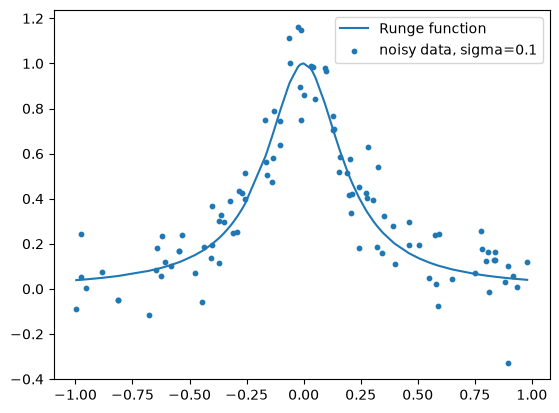

In [123]:
# The data of project 1, as a starting point for part b)
np.random.seed(2026)

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100 # 350 in Project 1
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1 # 0.25 in Project 1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
Y = y.reshape(-1, 1)  # make y a column vector for the network
print(X.shape, Y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()

## Data processing
Creates a design matrice out of input values x of chosen degree and  an array out of targets y.   
Splits the data into training and test data and 
scales the data, if "Split and scale" as Process input.

In [58]:
from sklearn.model_selection import train_test_split

def Data_process(x, y,
    test_size = 0.3, Process=None):
    X = np.asarray(x).reshape(-1, 1) # make X a column vector for the network
    y = np.asarray(y).reshape(-1, 1) # make y a column vector for the network


    if Process == "Split and scale":
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=2026
        )

        # Scale polynomial features, leaving the intercept column unchanged.
        mean = X_train[:, 1:].mean(axis=0)
        std = X_train[:, 1:].std(axis=0)
        std[std == 0] = 1

        X_train[:, 1:] = (X_train[:, 1:] - mean) / std
        X_test[:, 1:] = (X_test[:, 1:] - mean) / std

        # I choose not to scale the target.
        #y_mean = y_train.mean(axis=0)
        #y_train_c = y_train - y_mean

        return X_train, X_test, y_train, y_test #y_train_c, y_test, y_mean
    
    if Process == "Scale":
        mean = X[:, 1:].mean(axis=0) 
        std = X[:, 1:].std(axis=0)
        std[std == 0] = 1
        
        X[:, 1:] = (X[:, 1:] - mean) / std

        # I choose not to scale the target.
        #y_mean = y.mean(axis=0)
        #y_c = y - y_mean
        
        return X, y  #y_c, y_mean

    if Process == None:
        return X, y

## Activation functions and MSE


In [ ]:
def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))
def sigmoid_der(z):
    s = sigmoid(z)
    return s*(1 - s)
# Alternatively sigmoid_der = jax.grad(jnp.sum(sigmoid(z)))
# Identity
def identity(z):
    return z

def identity_der(z):
    return np.ones_like(z)

# Defining some activation functions
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)
# Derivative of the ReLU function
def ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.0)

def mse(predict, target):
    return jnp.mean((predict - target) ** 2)
def mse_der(predict, target): # Derivative of cost function
    return 2*(predict - target)/predict.size # Mean brings a factor of 1/N, derivative brings factor 2
# Alternatively: mse_der = jax.grad(mse(predict, target))

def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)

def softmax_vec(z):
    """Compute softmax values for each set of scores in the vector z.
    Use this function when you use the activation function on one vector at a time."""
    e_z = jnp.exp(z - jnp.max(z))
    return e_z / jnp.sum(e_z)

def cross_entropy(predict, target):
    # Classification cost_fun
    return -jnp.mean(
        jnp.sum(target * jnp.log(predict), axis=1)
    )

set_epoch = 10

ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_der),
               "relu": (ReLU, ReLU_der),
               "identity": (identity, identity_der),
               "softmax": (softmax, None)}


OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax} 

## Neural Network Class: Batched
### LLM Declaration: 
#### NeuralNetwork()
I am using LLM chatgpt GPT-6 Luna for learning about the usage of classes.  
The skeleton is from "Exercisesweek42.ipynb" Exercise 8 of repository MachinelearningUiO. 
I am using this skeleton, along with the solution of exerciseweek42.ipynb, to create the class. 

OpenAI assistance with translating the functions 
into working class functions.
OpenAI help with debugging the jax gradients.
OpenAI help with debugging the compute_gradients.

#### Data_processing()
--> Changed y = np.asarray(y) into y = npasarray(y).reshape(-1,1) to get y into the right shape (n,) - > (n,1) : Why this is so i do not understand, but i do understand that without this change, the code wont work in the feed forward saver as the dimensions of the last layer get off.


### Caution
Gradient methods should by handled outside, by performing
general operations on layer_grad list using functions
or classes seperate from the neural network.  
I still chose to include a short plain gradient descent
method for evolving the gradients, for testing.

In [17]:
class NeuralNetwork:
    def __init__(
        self,
        network_input_size,
        layer_output_sizes,
        activation_funcs,
        activation_ders,
        cost_fun,
        cost_der,
        seed,
    ):
        self.network_input_size = network_input_size
        self.layer_output_sizes = layer_output_sizes
        self.activation_funcs = activation_funcs
        self.activation_ders = activation_ders 
        self.cost_fun = cost_fun
        self.cost_der = cost_der
        self.rng = np.random.default_rng(seed) # Reproducability

        # create layers = [(W , b)] with random normal weights and biases
        layers = []

        i_size = network_input_size
        for layer_output_size in layer_output_sizes:
            W = self.rng.standard_normal((i_size, layer_output_size)) / np.sqrt(i_size) # dele på sqrt(i_size)? Ja for batched
            b = np.zeros(layer_output_size) + 0.01 #np.random.randn(layer_output_size)
            layers.append((W, b))

            i_size = layer_output_size
        
        self.layers = layers

    def predict(self, inputs):
        # Simple feed forward pass
        a = jnp.asarray(inputs) 
        for (W, b), activation_func in zip(self.layers, self.activation_funcs):
            z = a @ W + b
            a = activation_func(z)
        return a

    def cost(self, inputs, targets):
        predictions = self.predict(inputs)
        #print("Prediksjoner:", predictions.shape)
        #print("Fasit:", targets.shape)
        #print("Kostfunksjon:", self.cost_fun.__name__)

        mse = self.cost_fun(predictions,targets)
        return mse

    def _feed_forward_saver(self, inputs):
        layer_inputs = []
        zs = []
        a = jnp.asarray(inputs)
        for (W, b), activation_func in zip(self.layers, self.activation_funcs):
            layer_inputs.append(a)
            #print("a",a.shape)
            #print("W",W.shape)
            #print("b", b.shape)
            z = a @ W + b
            zs.append(z)
            a = activation_func(z)
        return layer_inputs, zs, a 

    def compute_gradient_standard(self, inputs, targets):
        # Backpropagation
        # dC_dW = dC_da @ da_dz @ dz_dW
        # dC_db = dC_da @ da_dz @ dz_db
        layer_inputs, sz, predict = self._feed_forward_saver(
            inputs)
        layer_grads = [() for layer in self.layers]

        for l in reversed(range(len(self.layers))):
            layer_input, z, activation_der = layer_inputs[l], sz[l], self.activation_ders[l]

            if l == (len(self.layers) - 1): # last layer
                dC_da = self.cost_der(predict, targets)
            else:
                (W, b) = self.layers[l + 1]
                #print("layer", l)
                #print("predictions:", predict.shape)
                #print("targets:", targets.shape)
                #print("dC_dz:", dC_dz.shape)
                #print("W:", W.shape)
                dC_da = dC_dz @ (W.T) 

            dC_dz = dC_da * activation_der(z) # Hadamard
            dC_dW = layer_input.T @ dC_dz
            dC_db = np.sum(dC_dz, axis=0) # what happened here?

            layer_grads[l] = (dC_dW, dC_db)
            #print("layer", l)
            #print("predictions:", predict.shape)
            #print("targets:", targets.shape)
            #print("dC_dz:", dC_dz.shape)
        return layer_grads

    def compute_gradient_softmax(self, inputs, targets):
        "Exercicesweek42.ipynb"
        layer_inputs, sz, predict = self._feed_forward_saver(inputs)
        layer_grads = [None] * len(self.layers) # AI assisted for simplicity GPT LUNA 6.1
        n = inputs.shape[0]

        for l in reversed(range(len(self.layers))):
            layer_input = layer_inputs[l]

            if l == len(self.layers) - 1:
                # Softmax + mean cross entropy
                dC_dz  = (predict - targets)/n
            else:
                (W, b) = self.layers[l + 1] # W_next, b_next
                z = sz[l]
                activation_der = self.activation_ders[l]
                dC_dz = (dC_dz @ W.T) * activation_der(z)
        
            dC_dW = layer_input.T @ dC_dz
            dC_db = np.sum(dC_dz, axis = 0)

            layer_grads[l] = (dC_dW, dC_db)

        return layer_grads

    def compute_gradient(self, inputs, targets):
        "AI Declaration: Created with help of GPT-6.1 Sol for SGD function compute_gradient"
        if self.activation_funcs[-1] is softmax:
            return self.compute_gradient_softmax(inputs, targets)

        return self.compute_gradient_standard(inputs, targets)

    
    def accuracy(self, predictions, targets):
        "Exerciseweek42: Classification"
        one_hot_predictions = np.zeros(predictions.shape)

        for i, prediction in enumerate(predictions):
            one_hot_predictions[i, np.argmax(prediction)] = 1
        return accuracy_score(one_hot_predictions, targets) # ski-kit function

    # These last two methods are not needed in the project, but they can be nice to have!
    # This should be External! But i can try use plain gradient
    # BEWARE: Using this function will change the local variable self.layers in the object
    def update_weights_plain(self, layer_grads, gamma=0.05):
        self.layers = [
        (W - gamma * W_g, b - gamma * b_g)
        for (W, b), (W_g, b_g) in zip(self.layers, layer_grads)]


    # jax solution
    # The first one has a layers parameter so that you can use jax.grad on it.
    
    def jax_compliant_predict(self, layers, inputs):
        a = jnp.asarray(inputs)

        for (W, b), activation_func in zip(layers, self.activation_funcs):
            z = a @ W + b
            a = activation_func(z)
        return a

    def jax_cost(self, layers, inputs, targets):
        predictions = self.jax_compliant_predict(layers, inputs)
        mse = self.cost_fun(predictions, targets)
        return mse

    def jax_gradient(self, inputs, targets):
        grads = jax.grad(self.jax_cost,argnums = 0)(self.layers, inputs, targets)
        return grads

## Class Optimizer

In [18]:
class Optimizer:
    """Oppdaterer nettverkslag med plain gradient descent, Adam eller RMSprop."""

    def __init__(
        self, method, gamma,
        beta1=0.9, beta2=0.999, rho=0.99, eps=1e-8
    ):
        self.method = method.lower()
        self.gamma = gamma
        self.beta1 = beta1
        self.beta2 = beta2
        self.rho = rho
        self.eps = eps

        self.state = None
        self.t = 0

    def zero_state(self, layers):
        """Lag nullstilte momentverdier for Adam og RMSprop."""
        return [
            (
                np.zeros_like(W),  # mW
                np.zeros_like(b),  # mb
                np.zeros_like(W),  # vW
                np.zeros_like(b),  # vb
            )
            for W, b in layers
        ]

    def initialize(self, layers):
        """Start en ny treningskjøring."""
        self.t = 0

        if self.method == "plain":
            self.state = None
        else:
            self.state = self.zero_state(layers)

    def step(self, layers, layer_grads, gamma=None):
        """Utfør én minibatchoppdatering."""
        if gamma is None:
            gamma = self.gamma

        self.t += 1

        if self.method == "plain":
            return self.step_plain(layers, layer_grads, gamma)

        if self.state is None:
            raise RuntimeError("Kjør optimizer.initialize(layers) før trening.")

        if self.method == "adam":
            return self.step_adam(layers, layer_grads, gamma)

        if self.method == "rmsprop":
            return self.step_rmsprop(layers, layer_grads, gamma)

        raise ValueError("method må være 'plain', 'adam' eller 'rmsprop'")

    def step_plain(self, layers, layer_grads, gamma):
        return [
            (W - gamma * dW, b - gamma * db)
            for (W, b), (dW, db) in zip(layers, layer_grads)
        ]

    def step_rmsprop(self, layers, layer_grads, gamma):
        new_layers = []
        new_state = []

        for (W, b), (dW, db), (mW, mb, vW, vb) in zip(
            layers, layer_grads, self.state
        ):
            dW = np.asarray(dW)
            db = np.asarray(db)

            vW = self.rho * vW + (1 - self.rho) * dW**2
            vb = self.rho * vb + (1 - self.rho) * db**2

            W = W - gamma * dW / (np.sqrt(vW) + self.eps)
            b = b - gamma * db / (np.sqrt(vb) + self.eps)

            new_layers.append((W, b))
            new_state.append((mW, mb, vW, vb))

        self.state = new_state
        return new_layers

    def step_adam(self, layers, layer_grads, gamma):
        new_layers = []
        new_state = []

        for (W, b), (dW, db), (mW, mb, vW, vb) in zip(
            layers, layer_grads, self.state
        ):
            dW = np.asarray(dW)
            db = np.asarray(db)

            mW = self.beta1 * mW + (1 - self.beta1) * dW
            mb = self.beta1 * mb + (1 - self.beta1) * db
            vW = self.beta2 * vW + (1 - self.beta2) * dW**2
            vb = self.beta2 * vb + (1 - self.beta2) * db**2

            mW_hat = mW / (1 - self.beta1**self.t)
            mb_hat = mb / (1 - self.beta1**self.t)
            vW_hat = vW / (1 - self.beta2**self.t)
            vb_hat = vb / (1 - self.beta2**self.t)

            W = W - gamma * mW_hat / (np.sqrt(vW_hat) + self.eps)
            b = b - gamma * mb_hat / (np.sqrt(vb_hat) + self.eps)

            new_layers.append((W, b))
            new_state.append((mW, mb, vW, vb))

        self.state = new_state
        return new_layers

## Func SGD Train

In [19]:
def step_length(t, t0, t1):
    """A decaying learning-rate schedule."""
    return t0 / (t + t1)

def train_sgd(
    network, X, y, method="adam",
    epochs=set_epoch, batch_size=5, gamma=0.001, lmb = 0.0, penalty ="l2", schedule=None, seed=2026
):
    "LLM Assisted: Using the class netowrk"
    rng = np.random.default_rng(seed)

    X = np.asarray(X)
    y = np.asarray(y) #.reshape(-1, 1)

    # Bruk av klasse
    optimizer = Optimizer(method=method, gamma=gamma)
    optimizer.initialize(network.layers)

    # Tilstanden er en liste med tupler, ett for hvert lag.
    state = None if method == "plain" else optimizer.zero_state(network.layers)
    t = 0
    history = []
    history_test = []
    
    for epoch in range(epochs):
        # Bland rekkefølgen på datapunktene for hver epoke.
        indices = rng.permutation(len(X))
        # Minibatch
        for start in range(0, len(X), batch_size):
            batch = indices[start:start + batch_size]

            X_batch = X[batch]
            y_batch = y[batch]

            # Hent gradientene fra nettverksobjektet.
            layer_grads = network.compute_gradient(X_batch, y_batch)

            #L2 norm - Ridge
            "AI Declaration: Help from codex GPT-LUNA6.1 for task 2b) L1 and L2 placement"
            if penalty == "l2":
                layer_grads = [
                (dW + 2 * lmb * W, db)
                for (W, b), (dW, db) in zip(network.layers, layer_grads)]
            #L1 norm - Lasso
            #"AI Declaration: Help from codex GPT-Luna6.1"
            elif penalty == "l1":
                layer_grads = [
                (dW + lmb * np.sign(W), db)
                for (W, b), (dW, db) in zip(network.layers, layer_grads)
                ]
            elif penalty is not None:
                raise ValueError("penalty må være 'l1', 'l2' eller None")

            # Tell minibatchoppdateringer. Adam bruker t til korreksjon
            # for oppstartsfasen.
            t += 1
            gamma = gamma if schedule is None else step_length(t - 1, *schedule)
            network.layers = optimizer.step(network.layers, layer_grads)

        # Kostnaden etter at hele treningssettet har vært gjennom én gang.
        epoch_cost = float(network.cost(X, y))
        history.append(epoch_cost)
    

    return history, network.layers

## Func PGD train

In [48]:
def train_plain(
    network, X, y, gamma=0.001, lmb = 0.0, penalty = None, epochs=set_epoch, seed = 2026
    ):
    rng = np.random.default_rng(seed)
    inputs = np.asarray(X)
    targets = np.asarray(y)
    
    optimizer = Optimizer(method="plain", gamma=gamma)
    optimizer.initialize(network.layers)
    state = None
    history = []
    

    for i in range(epochs):
        layer_grads = network.compute_gradient(inputs, targets)
        
        "Cope from SGD_train()"
        if penalty == "l2":
            layer_grads = [
            (dW + 2 * lmb * W, db)
            for (W, b), (dW, db) in zip(network.layers, layer_grads)]
        elif penalty == "l1":
            layer_grads = [
            (dW + lmb * np.sign(W), db)
            for (W, b), (dW, db) in zip(network.layers, layer_grads)
            ]
        elif penalty is not None:
            raise ValueError("penalty må være 'l1', 'l2' eller None")
        
        network.layers = optimizer.step(network.layers, layer_grads)
        
        cost = float(network.cost(inputs, targets))
        history.append((cost))
            

    return history, network.layers

## NeuralNetRegressor

In [79]:
class NeuralNetRegressor(BaseEstimator, RegressorMixin):
    """Your Project 2 network with the scikit-learn estimator interface."""

    def __init__(self, 
                hidden=(50,), activation="sigmoid", 
                gamma=0.01, lmbd=0.0, 
                penalty=None, method = "plain", 
                epochs=set_epoch, batch_size=10, 
                descent = "sgd", seed=2026):
        # store the hyperparameters under the same names; no computation here
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.penalty = penalty
        self.method = method
        self.epochs = epochs
        self.batch_size = batch_size
        self.descent = descent # This is a new parameter to choose between SGD and plain gradient descent
        self.seed = seed

    def fit(self, X, y):
        # X has shape (n, 1), y shape (n,): build the layers from self.seed,
        # train with your SGD for self.epochs epochs, store the layers in self.layers_

        """LLM Assistance: Creating the activation funcs in correct format"""
        hidden_func, hidden_der = ACTIVATIONS[self.activation]
        activation_funcs = [hidden_func] * len(self.hidden) + [identity]
        activation_ders = [hidden_der] * len(self.hidden) + [identity_der]

        self.network_ = NeuralNetwork(
            network_input_size=X.shape[1],
            layer_output_sizes=(*self.hidden,1), # LLM Assisted - Shape error
            activation_funcs= activation_funcs,
            activation_ders = activation_ders,
            cost_fun=mse,
            cost_der=mse_der,
            seed=self.seed
        )

        if self.descent == "sgd":
            self.history, self.layer = train_sgd(self.network_, X, y, method = self.method,
                                epochs = self.epochs, batch_size = self.batch_size, 
                                gamma = self.gamma, lmb = self.lmbd, penalty=self.penalty, seed = self.seed)
        elif self.descent == "plain":
            self.history, self.layer = train_plain(self.network_, X, y, gamma = self.gamma, lmb = self.lmbd, penalty=self.penalty, epochs = self.epochs, seed = self.seed)
        else:
            raise ValueError("descent must be 'sgd' or 'plain'")
        return self

    def predict(self, X):
        """LM Assisted: Use of class functionality
           LM Assisted: Reshaping of output array to 1D for Scikit""" 
        # the network output as a 1D array of length len(X)
        predictions = self.network_.predict(X)
        predictions_1D = np.asarray(predictions).reshape(-1)
        return predictions_1D

## Analysis and comparison of model


### LLM Declaration:
Exercices week44


In [ ]:
X, y = Data_process(x, y, Process="Scale")

cv = KFold(n_splits=5, shuffle=True, random_state=2026)
net = make_pipeline(StandardScaler(), NeuralNetRegressor(
        hidden=(50,), activation="sigmoid", 
        gamma=0.01, lmbd = 0.0, penalty=None, method = "plain", 
        epochs=set_epoch, batch_size=10, 
        descent = "sgd", seed=2026))


scores = -cross_val_score(net, X, y, cv=cv, scoring="neg_mean_squared_error")
res = cross_validate(net, X, y, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)

In [77]:
print("-cross_val_score:")
print(f"5-fold CV MSE {scores.mean():.4f} +/- {scores.std(ddof=1) / np.sqrt(len(scores)):.4f}")
print(f"folds: {scores}")
print("cross_validate:")
#print(res)
validation_mse = -res["test_score"]
training_mse = -res["train_score"]
print("5 Fold Test score:", validation_mse)
print("5 Fold train score:", training_mse)

mean_mse = validation_mse.mean()
std_error = validation_mse.std(ddof=1) / np.sqrt(len(validation_mse))

print(f"CV MSE: {mean_mse:.4f} +/- {std_error:.4f}")

print("The MSE is an approximate standard error of the mean MSE, since the folds in the training sets overlap, the scores are not independent")

-cross_val_score:
5-fold CV MSE 0.1490 +/- 0.0179
folds: [0.18764883 0.10798978 0.18765698 0.15438774 0.10734686]
cross_validate:
5 Fold Test score: [0.18764883 0.10798978 0.18765698 0.15438774 0.10734686]
5 Fold train score: [0.13983638 0.15314247 0.1393933  0.1427293  0.15498431]
CV MSE: 0.1490 +/- 0.0179
The MSE is an approximate standard error of the mean MSE, since the folds in the training sets overlap, the scores are not independent


# Learning rate and Method with GridSearchCV
- (50, ) vS (50, 100, )
* Learning Rates $\gamma$
* SGD: RMS, Adam, Plain
* PGD. 

Choose best model (One SE Rule):

A problem here is that for descent = "plain" the code 
 omits the method parameter, since the method is only used for SGD. 
 This means that the grid search will not test all combinations of 
 method and descent, which may lead to suboptimal results. 
 A possible solution is to create a custom estimator that 
 takes both method and descent as parameters, and then use that estimator in the grid search.
 ## Error
 Invalid parameter 'descent' for estimator NeuralNetRegressor(). Valid parameters are: ['activation', 'batch_size', 'epochs', 'gamma', 'hidden', 'lmbd', 'method', 'penalty', 'seed']

In [81]:
param_grid = {"neuralnetregressor__gamma": [0.001, 0.003, 0.01, 0.03, 0.1],
            "neuralnetregressor__method": ["rmsprop", "adam", "plain"],
            "neuralnetregressor__hidden": [(50,), (50, 100,)]}

search1 = GridSearchCV(net, param_grid, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
search1.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'neuralnetregressor__gamma': [0.001, 0.003, ...], 'neuralnetregressor__hidden': [(50,), (50, ...)], 'neuralnetregressor__method': ['rmsprop', 'adam', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-v

#### LLM Declaration
Used Copilot and Codex with GPT-Sol 6.1 to use dictionaries 
and find + store the best One-SE limit

In [ ]:
results = search1.cv_results_          # a dict of arrays, one entry per grid point
cv_mse_grid = -results["mean_test_score"]
cv_se_grid = results["std_test_score"] / np.sqrt(cv.get_n_splits() - 1)
#print("mse grid")
#print(cv_mse_grid)
#print("se grid")
#print(cv_se_grid)
print("-----")
best_estimator = search1.best_estimator_
best_params = search1.best_params_
print(best_estimator)
print(best_params)
print("-----")
print("Final Result:\n")
best_mse = -search1.best_score_  # Ved scoring="neg_mean_squared_error"
best_index = search1.best_index_
k = search1.n_splits_
best_se = search1.cv_results_["std_test_score"][best_index] / np.sqrt(k - 1)
best_gamma = best_params["neuralnetregressor__gamma"]
best_method = best_params["neuralnetregressor__method"]
best_hidden = best_params["neuralnetregressor__hidden"]

print(f"best_mse = {best_mse:.4f} +/- best_se = {best_se:.4f}")
print(f"gamma = {best_params["neuralnetregressor__gamma"]}") 
print(f"method = {best_params["neuralnetregressor__method"]}")
print(f"hidden = {best_params["neuralnetregressor__hidden"]}")
print("-------")
"AI Declaration: GPT-Luna6 help with indexing and for loop"
threshold = cv_mse_grid[best_index] + cv_se_grid[best_index]
print(f"One-SE limit:  {threshold:.5f}\n")
found = False
One_SE_candidates = {}
for i, params in enumerate(results["params"]):
    gamma = params["neuralnetregressor__gamma"]
    method = params["neuralnetregressor__method"]
    hidden = params["neuralnetregressor__hidden"]
    lmbd = 0.0  # Assuming lambda is not part of the grid
    if (cv_mse_grid[i] <= threshold and gamma > best_gamma and sum(hidden) < sum(best_hidden)):
        found = True
        print(
            f"gamma={gamma:g} "
            f"method={method},hidden={hidden}, "
            f"CV-MSE={cv_mse_grid[i]:.5f} +/- {cv_se_grid[i]:.5f}"
        )
        One_SE_candidates[(method, tuple(hidden), gamma)] = cv_mse_grid[i]

if not found:
    print("No architecture gave a CV-MSE within one SE of the lowest.")
best_key = min(One_SE_candidates, key=One_SE_candidates.get)
best_mse = One_SE_candidates[best_key]

print(f"One-SE best architecture: method={best_key[0]}, hidden={best_key[1]}, gamma={best_key[2]:g}, CV-MSE={best_mse:.5f}")

-----
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('neuralnetregressor',
                 NeuralNetRegressor(gamma=0.003, hidden=(50, 100),
                                    method='rmsprop'))])
{'neuralnetregressor__gamma': 0.003, 'neuralnetregressor__hidden': (50, 100), 'neuralnetregressor__method': 'rmsprop'}
-----
Final Result:

best_mse = 0.0703 +/- best_se = 0.0057
gamma = 0.003
method = rmsprop
hidden = (50, 100)
-------
One-SE limit:  0.07603

gamma=0.01 method=rmsprop,hidden=(50,), CV-MSE=0.07556 +/- 0.00602
gamma=0.01 method=adam,hidden=(50,), CV-MSE=0.07421 +/- 0.00590
gamma=0.03 method=rmsprop,hidden=(50,), CV-MSE=0.07315 +/- 0.00591
gamma=0.03 method=adam,hidden=(50,), CV-MSE=0.07390 +/- 0.00666
('rmsprop', (50,), 0.03)
0.07314746171715979
One-SE best architecture: method=rmsprop, hidden=(50,), gamma=0.03, CV-MSE=0.07315


#### LLM Declaration:
Codex GPT-Sol 6.1 used to generate the Heatmap of the results with 1-SE limit and lowest MSE of all 1-SE candidates.

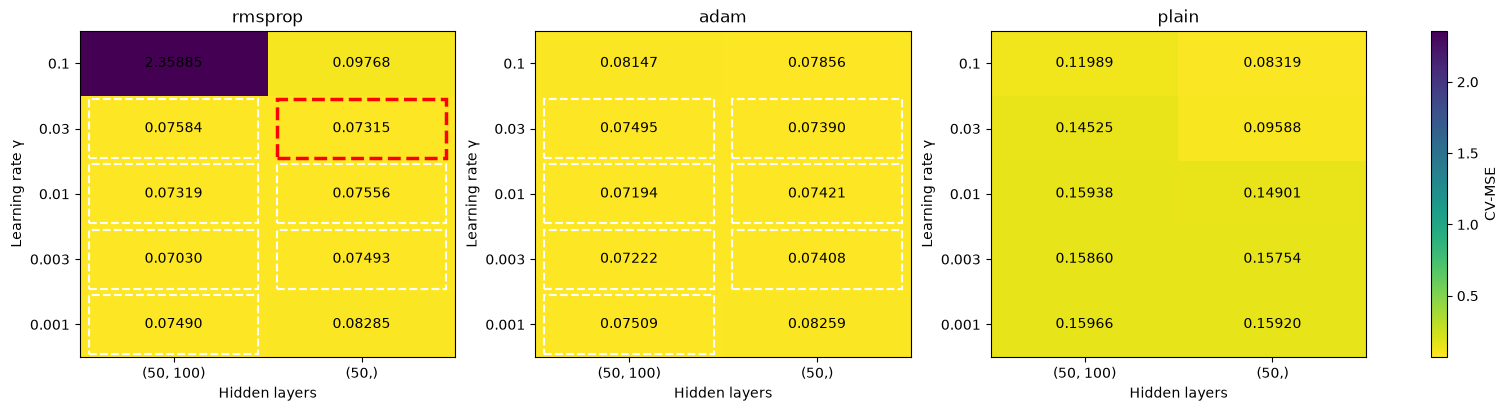

In [118]:

results = search1.cv_results_

best_index = search1.best_index_
best_mse = -results["mean_test_score"][best_index]
best_se = (
    results["std_test_score"][best_index]
    / np.sqrt(search1.n_splits_ - 1)
)
threshold = best_mse + best_se
selected_key = min(One_SE_candidates, key=One_SE_candidates.get)
selected_method, selected_hidden, selected_gamma = selected_key

df = pd.DataFrame([
    {
        "method": p["neuralnetregressor__method"],
        "hidden": str(p["neuralnetregressor__hidden"]),
        "gamma": p["neuralnetregressor__gamma"],
        "MSE": -score,
    }
    for p, score in zip(
        results["params"], results["mean_test_score"]
    )
])

methods = df["method"].unique()
fig, axes = plt.subplots(
    1, len(methods),
    figsize=(5 * len(methods), 4),
    squeeze=False,
    constrained_layout=True,
)

for ax, method in zip(axes[0], methods):
    grid = df[df["method"] == method].pivot(
        index="gamma", columns="hidden", values="MSE"
    ).sort_index()

    im = ax.imshow(
        grid.values,
        origin="lower",
        aspect="auto",
        cmap="viridis_r",
        vmin=df["MSE"].min(),
        vmax=df["MSE"].max(),
    )

    ax.set_xticks(range(len(grid.columns)), grid.columns)
    ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set_xlabel("Hidden layers")
    ax.set_ylabel("Learning rate γ")
    ax.set_title(method)

    for (row, col), value in np.ndenumerate(grid.values):
        ax.text(
            col, row, f"{value:.5f}",
            ha="center", va="center", color="black"
        )

        if value <= threshold:
            is_selected = (
                method == selected_method
                and grid.columns[col] == str(selected_hidden)
                and np.isclose(grid.index[row], selected_gamma)
            )

            ax.add_patch(plt.Rectangle(
                (col - 0.45, row - 0.45),
                0.9, 0.9,
                fill=False,
                edgecolor="red" if is_selected else "white",
                linestyle="--",
                linewidth=2.5 if is_selected else 1.5,
            ))
fig.colorbar(im, ax=axes.ravel().tolist(), label="CV-MSE")
plt.show()

## OLS comparison

In [124]:
degrees = range(1, 16)
poly_OLS = make_pipeline(StandardScaler(), PolynomialFeatures(), LinearRegression())
ols = GridSearchCV(poly_OLS, {"polynomialfeatures__degree": degrees}, cv=cv, scoring="neg_mean_squared_error", return_train_score=True)
ols.fit(X, y) # Drives the fitting: 15 degree x 5 folds = 75 models

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'polynomialfeatures__degree': range(1, 16)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be d

In [125]:
k = cv.get_n_splits()
r = ols.cv_results_
poly = ({"ols": ols, 
        "degrees": list(degrees), 
        "ols_mse": -r["mean_test_score"],
        "ols_se": r["std_test_score"] / np.sqrt(k - 1), 
        "ols_train": -r["mean_train_score"]})

d_O = poly["ols"].best_params_["polynomialfeatures__degree"] # OLS best degree

#print("OLS, CV MSE by degree:   ", np.round(poly["ols_mse"], 4))
#print("OLS, standard error:     ", np.round(poly["ols_se"], 4))
#print("OLS, training MSE:       ", np.round(poly["ols_train"], 4))
print(f"OLS: best degree {d_O}, CV MSE {-poly['ols'].best_score_:.4f} +/- {poly['ols_se'][d_O - 1]:.4f}, {d_O + 1} parameters")

OLS: best degree 11, CV MSE 0.0211 +/- 0.0032, 12 parameters


## OLS One SE Rule
LLM Declaration: Changes from exercicesweek44 to solve for OLS degree done with GPT-Sol 6.1 in Codex.

In [126]:
ols_results = ols.cv_results_
ols_mse = -ols_results["mean_test_score"]
ols_se = (
    ols_results["std_test_score"]
    / np.sqrt(ols.n_splits_ - 1)
)

best_index = ols.best_index_
best_mse = ols_mse[best_index]
best_se = ols_se[best_index]
threshold = best_mse + best_se

print(f"Best OLS degree: {d_O}")
print(f"Lowest OLS CV-MSE: {best_mse:.5f}")
print(f"One-SE limit: {threshold:.5f}\n")

candidates = {}

for i, params in enumerate(ols_results["params"]):
    degree = params["polynomialfeatures__degree"]

    if degree < d_O and ols_mse[i] <= threshold:
        candidates[degree] = ols_mse[i]

        print(
            f"degree={degree}: "
            f"CV-MSE={ols_mse[i]:.5f} +/- {ols_se[i]:.5f}"
        )

# One-SE-regelen velger laveste kvalifiserte polynomgrad.
selected_degree = min(candidates) if candidates else d_O

print(f"\nOne-SE selected degree: {selected_degree}")

Best OLS degree: 11
Lowest OLS CV-MSE: 0.02111
One-SE limit: 0.02435

degree=8: CV-MSE=0.02253 +/- 0.00172
degree=9: CV-MSE=0.02376 +/- 0.00121
degree=10: CV-MSE=0.02400 +/- 0.00285

One-SE selected degree: 8


## OLS Comparison with Network
#### LLM Declaration: GPT-sol 6.1 with Codex
This code is a recreation of exercicesweek44 with help of LLM. 
Full use of Pandas is done by LLM

In [150]:
"AI assisted table"


def result_row(name, model, n_params, index=None):
    # Default to the minimum-MSE candidate.
    if index is None:
        index = model.best_index_

    results = model.cv_results_
    mse = -results["mean_test_score"][index]
    se = results["std_test_score"][index] / np.sqrt(model.n_splits_ - 1)

    settings = {
        key.split("__")[-1]: value
        for key, value in results["params"][index].items()
    }

    return {
        "Model": name,
        "Architecture": ", ".join(
    f"{key}={value}" for key, value in settings.items()),
        "CV MSE ± SE": f"{mse:.5f} ± {se:.5f}",
        "Parameters": n_params,
        "Fit time (ms)": round(results["mean_fit_time"][index] * 1000, 1),
    }

comparison = pd.DataFrame([
    result_row("Network", search1, network_params),
    result_row(
        "OLS", ols,
        ols.best_params_["polynomialfeatures__degree"] + 1,
    ),
]).set_index("Model")

display(comparison)

# ONE SE Limit
def count_network_params(hidden, n_inputs):
    sizes = (n_inputs, *hidden, 1)
    return sum(
        (n_in + 1) * n_out
        for n_in, n_out in zip(sizes[:-1], sizes[1:])
    )


rows = []
one_se_indices = {}
for name, model in [("Network", search1), ("OLS", ols)]:
    results = model.cv_results_
    cv_mse = -results["mean_test_score"]
    cv_se = (
        results["std_test_score"]
        / np.sqrt(model.n_splits_ - 1)
    )

    best_index = model.best_index_
    threshold = cv_mse[best_index] + cv_se[best_index]
    eligible = np.flatnonzero(cv_mse <= threshold)

    if name == "OLS":
        selected = min(
            eligible,
            key=lambda i: (
                results["params"][i]["polynomialfeatures__degree"],
                cv_mse[i],
            ),
        )
        params = results["params"][selected]
        degree = params["polynomialfeatures__degree"]

        settings = f"degree={degree}"
        n_params = degree + 1

    else:
        n_inputs = model.best_estimator_.n_features_in_

        selected = min(
            eligible,
            key=lambda i: (
                count_network_params(
                    results["params"][i]["neuralnetregressor__hidden"],
                    n_inputs,
                ),
                cv_mse[i],
            ),
        )

        params = results["params"][selected]
        hidden = params["neuralnetregressor__hidden"]
        method = params["neuralnetregressor__method"]
        gamma = params["neuralnetregressor__gamma"]

        settings = (
            f"hidden={hidden}, method={method}, gamma={gamma:g}"
        )
        n_params = count_network_params(hidden, n_inputs)
    one_se_indices[name] = selected
    rows.append({
        "Model": name,
        "One-SE selection": settings,
        "CV MSE ± SE": (
            f"{cv_mse[selected]:.5f} ± {cv_se[selected]:.5f}"
        ),
        "Parameters": n_params,
        "Fit time (ms)": round(
            results["mean_fit_time"][selected] * 1000, 1
        ),
    })

comparison_one_se = pd.DataFrame(rows).set_index("Model")
display(comparison_one_se)

,Architecture,CV MSE ± SE,Parameters,Fit time (ms)
Model,,,,
Network,"gamma=0.003, hidden=(50, 100), method=rmsprop",0.07030 ± 0.00574,5301,14822.8
OLS,degree=11,0.02111 ± 0.00324,12,7.8


,One-SE selection,CV MSE ± SE,Parameters,Fit time (ms)
Model,,,,
Network,"hidden=(50,), method=rmsprop, gamma=0.03",0.07315 ± 0.00591,151,18643.9
OLS,degree=8,0.02253 ± 0.00172,9,6.2


# Test Set

In [174]:
from sklearn.base import clone

rng_test = np.random.default_rng(1)
x_test = np.sort(rng_test.uniform(-1.0, 1.0, 100))
y_test = runge(x_test) + rng_test.normal(0.0, sigma, 100)
X_test = x_test.reshape(-1, 1)


def evaluate_mse(model, X_test, y_test):
    predictions = np.asarray(model.predict(X_test)).ravel()
    targets = np.asarray(y_test).ravel()
    return np.mean((predictions - targets) ** 2)


# Modellene med lavest CV-MSE
NN_t = search1.best_estimator_
ols_t = ols.best_estimator_
print(NN_t)
print("GridSearchCV best estimator")
print(f"NN:  MSE = {evaluate_mse(NN_t, X_test, y_test):.4f}")
print(f"OLS: MSE = {evaluate_mse(ols_t, X_test, y_test):.4f}")


# Modellene valgt etter One-SE-regelen
# LLM Declaration: GPT Sol-6.1 used to find the ONE-SE models and clone it with sklearn.base clone module.
# Got set_params which sets the ONE_se parameters one the search model.
one_se_models = {}

for name, search in [("OLS", ols), ("Network", search1)]:
    index = one_se_indices[name]
    params = search.cv_results_["params"][index]

    model = clone(search.estimator).set_params(**params)
    model.fit(X, Y)

    one_se_models[name] = model

NN_SE = one_se_models["Network"]
OLS_SE = one_se_models["OLS"]

print("\nOne-SE selection")
print(f"NN:  MSE = {evaluate_mse(NN_SE, X_test, y_test):.4f}")
print(f"OLS: MSE = {evaluate_mse(OLS_SE, X_test, y_test):.4f}")

print(NN_SE)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('neuralnetregressor',
                 NeuralNetRegressor(gamma=0.003, hidden=(50, 100),
                                    method='rmsprop'))])
GridSearchCV best estimator
NN:  MSE = 0.0146
OLS: MSE = 0.0133

One-SE selection
NN:  MSE = 0.0130
OLS: MSE = 0.0149
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('neuralnetregressor',
                 NeuralNetRegressor(gamma=0.03, method='rmsprop'))])


In [173]:
import pandas as pd

rows = []

for name, selection, model in [
    ("Network", "Lowest CV-MSE", NN_t),
    ("OLS", "Lowest CV-MSE", ols_t),
    ("Network", "One-SE", NN_SE),
    ("OLS", "One-SE", OLS_SE),
]:
    rows.append({
        "Model": name,
        "Selection": selection,
        "Test MSE": evaluate_mse(model, X_test, y_test),
    })

comparison_test = pd.DataFrame(rows).set_index(["Model", "Selection"])

display(
    comparison_test.style.format({"Test MSE": "{:.5f}"})
)

,,Test MSE
Model,Selection,
Network,Lowest CV-MSE,0.01456
OLS,Lowest CV-MSE,0.01326
Network,One-SE,0.01300
OLS,One-SE,0.01495
